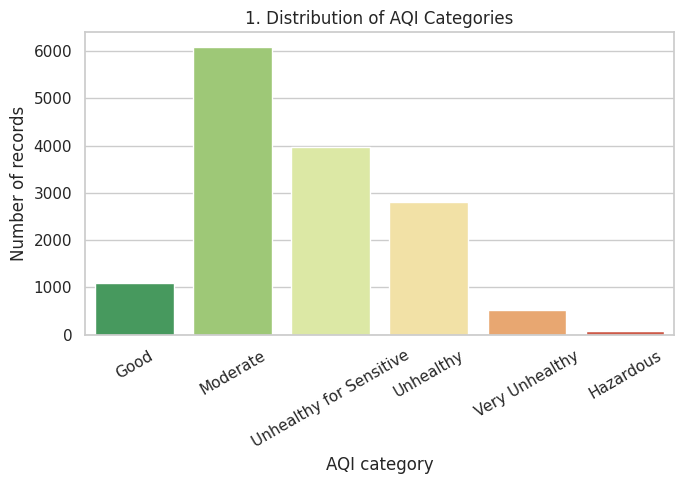

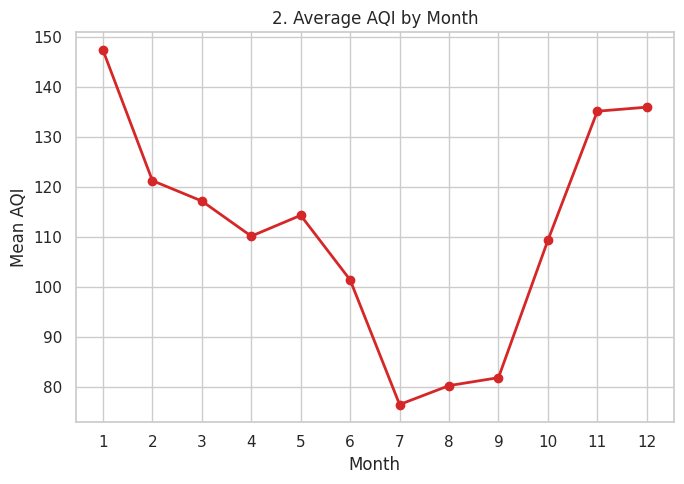

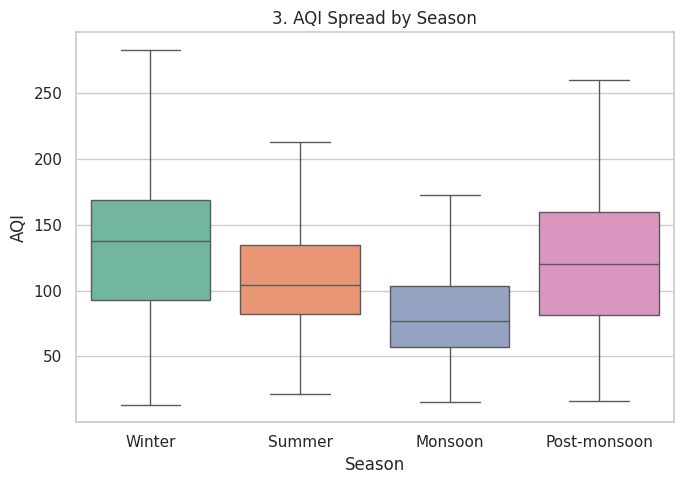

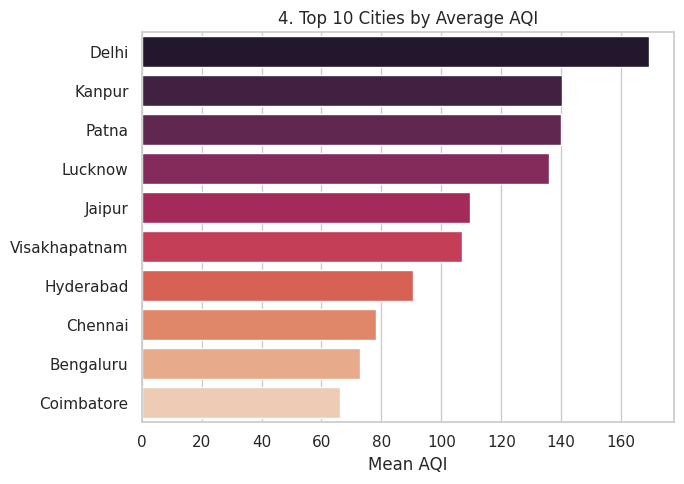

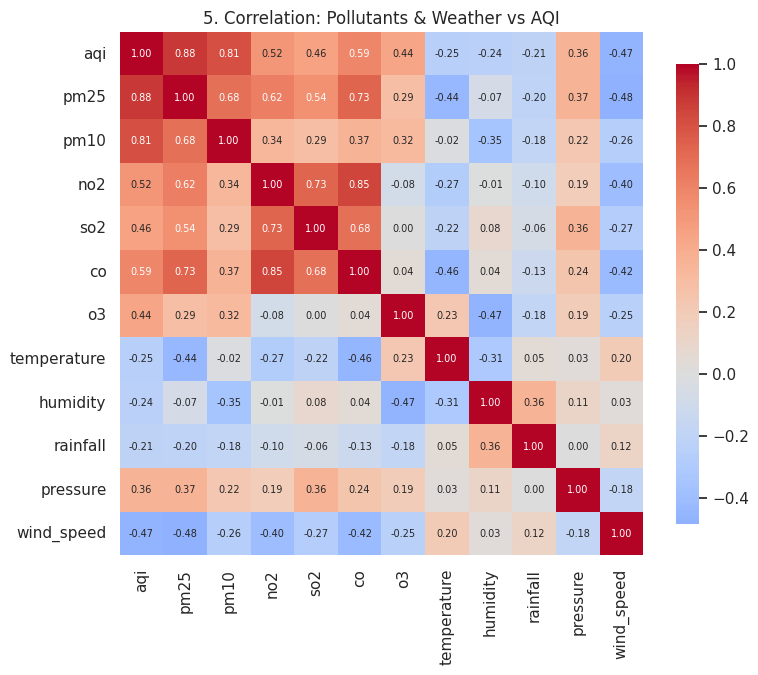

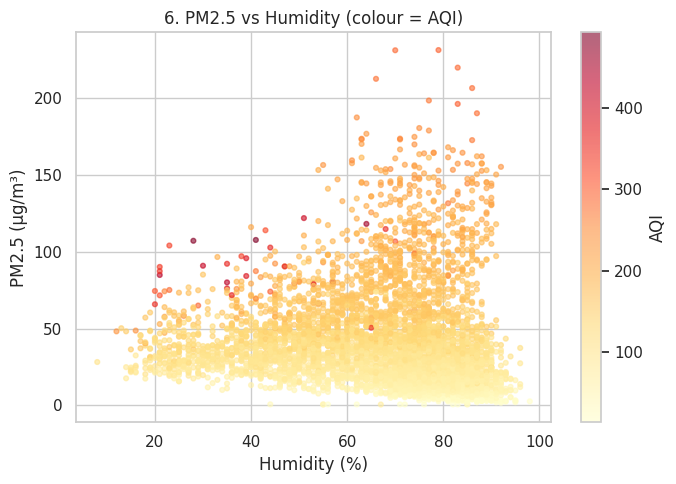

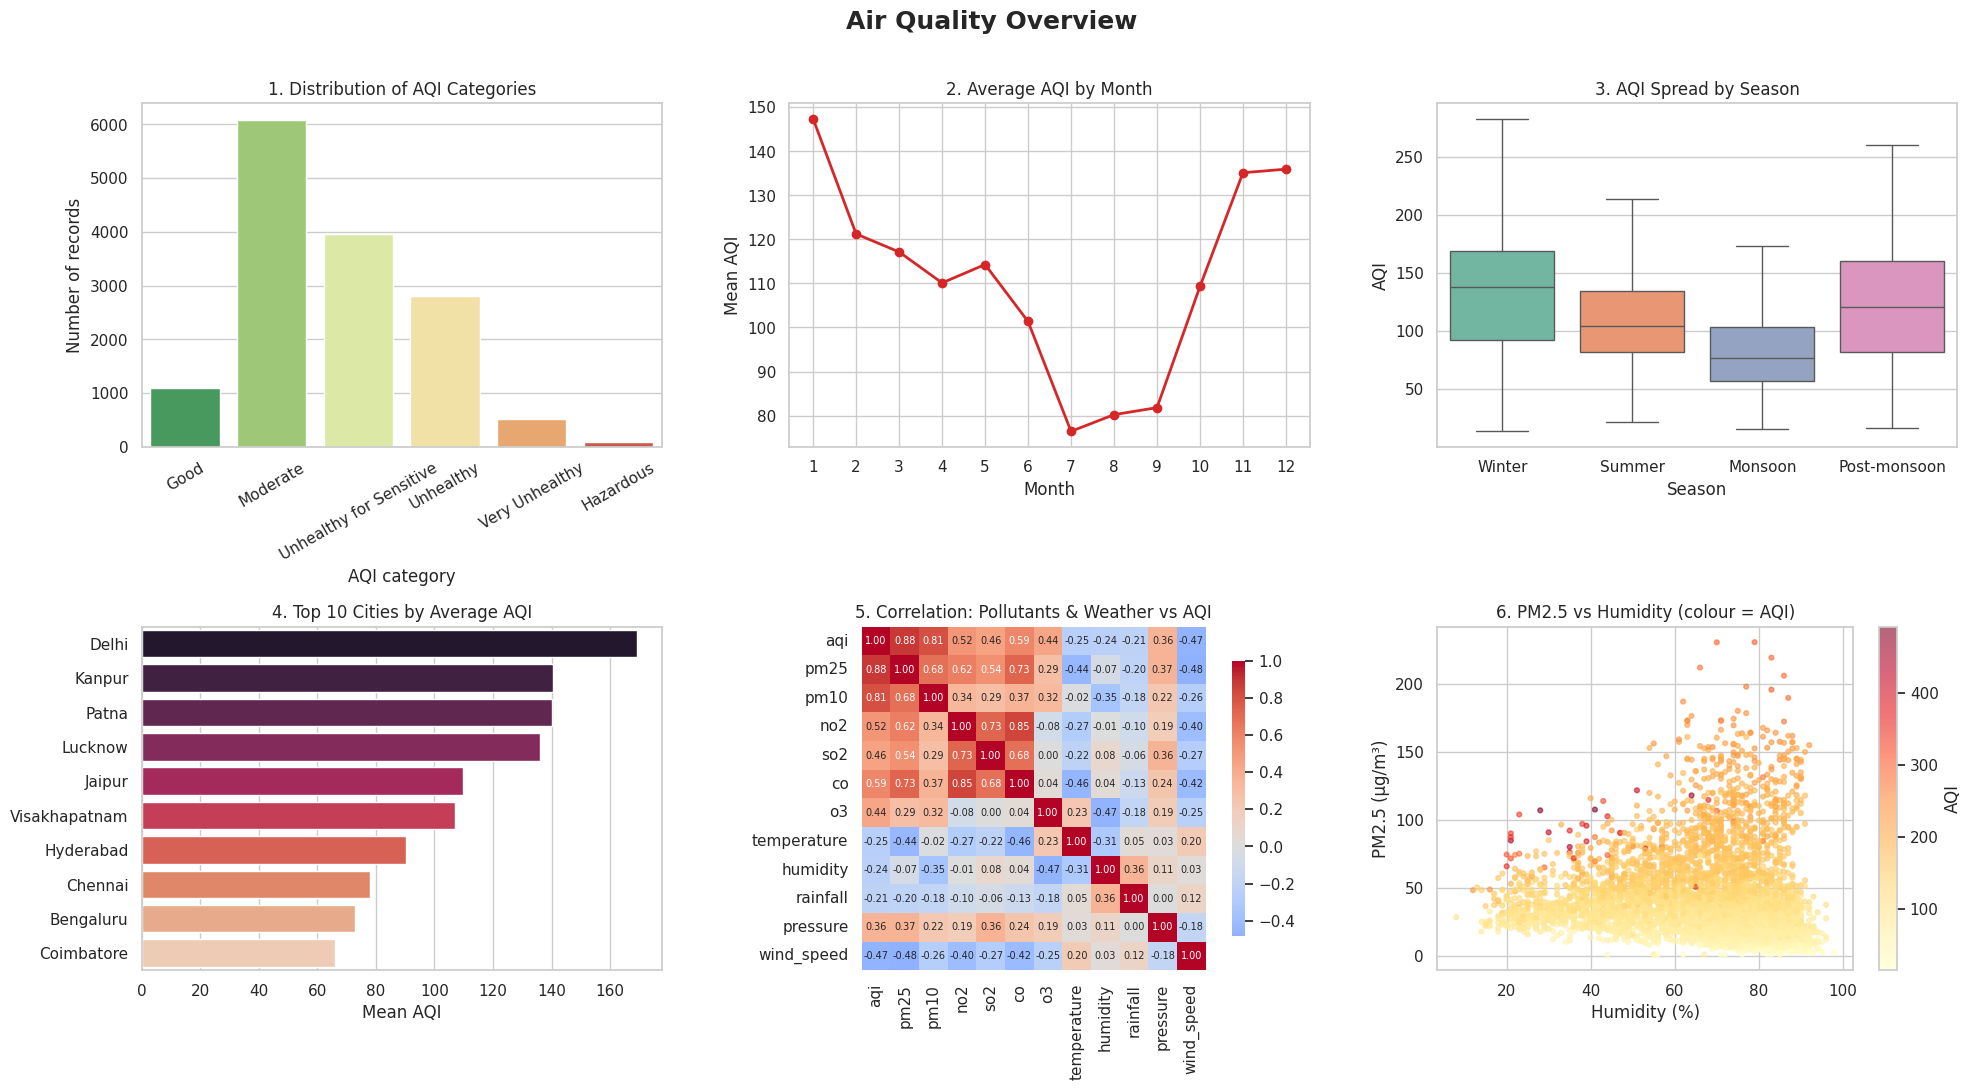

In [ ]:
"""
Air quality visualizations for cleaned_data.csv
Produces 6 graphs (saved individually as PNGs + one combined dashboard).

Requirements: pip install pandas matplotlib seaborn
Run:          python visualize_air_quality.py
"""

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

CSV_PATH = "cleaned_data.csv"

sns.set_theme(style="whitegrid", context="notebook")

# ---------- Load & prepare ----------
df = pd.read_csv(CSV_PATH, parse_dates=["time"])

category_order = ["Good", "Moderate", "Unhealthy for Sensitive", "Unhealthy", "Very Unhealthy", "Hazardous"]
present = [c for c in category_order if c in df["aqi_category"].unique()]
# Fall back to whatever labels exist if they differ from the US EPA AQI names
if not present:
    present = list(df["aqi_category"].dropna().unique())

season_order = [s for s in ["Winter", "Summer", "Monsoon", "Post-monsoon"]
                if s in df["season"].unique()] or list(df["season"].dropna().unique())

# ---------- 1. AQI category distribution ----------
def plot_category_counts(ax):
    counts = df["aqi_category"].value_counts().reindex(present).dropna()
    sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette="RdYlGn_r",
                legend=False, ax=ax)
    ax.set_title("1. Distribution of AQI Categories")
    ax.set_xlabel("AQI category")
    ax.set_ylabel("Number of records")
    ax.tick_params(axis="x", rotation=30)

# ---------- 2. Monthly average AQI trend ----------
def plot_monthly_trend(ax):
    monthly = df.groupby("month")["aqi"].mean()
    ax.plot(monthly.index, monthly.values, marker="o", linewidth=2, color="tab:red")
    ax.set_title("2. Average AQI by Month")
    ax.set_xlabel("Month")
    ax.set_ylabel("Mean AQI")
    ax.set_xticks(range(1, 13))

# ---------- 3. AQI by season (box plot) ----------
def plot_season_box(ax):
    sns.boxplot(data=df, x="season", y="aqi", order=season_order, hue="season",
                hue_order=season_order, palette="Set2", legend=False,
                showfliers=False, ax=ax)
    ax.set_title("3. AQI Spread by Season")
    ax.set_xlabel("Season")
    ax.set_ylabel("AQI")

# ---------- 4. Top 10 most polluted cities ----------
def plot_top_cities(ax):
    top = df.groupby("city")["aqi"].mean().sort_values(ascending=False).head(10)
    sns.barplot(x=top.values, y=top.index, hue=top.index, palette="rocket",
                legend=False, ax=ax)
    ax.set_title("4. Top 10 Cities by Average AQI")
    ax.set_xlabel("Mean AQI")
    ax.set_ylabel("")

# ---------- 5. Correlation heatmap ----------
def plot_corr_heatmap(ax):
    cols = ["aqi", "pm25", "pm10", "no2", "so2", "co", "o3",
            "temperature", "humidity", "rainfall", "pressure", "wind_speed"]
    cols = [c for c in cols if c in df.columns]
    corr = df[cols].corr()
    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0,
                square=True, cbar_kws={"shrink": 0.8}, annot_kws={"size": 7}, ax=ax)
    ax.set_title("5. Correlation: Pollutants & Weather vs AQI")

# ---------- 6. PM2.5 vs humidity, coloured by AQI ----------
def plot_pm25_humidity(ax):
    sample = df.sample(min(len(df), 5000), random_state=42)  # keep the plot readable
    sc = ax.scatter(sample["humidity"], sample["pm25"], c=sample["aqi"],
                    cmap="YlOrRd", s=12, alpha=0.6)
    plt.colorbar(sc, ax=ax, label="AQI")
    ax.set_title("6. PM2.5 vs Humidity (colour = AQI)")
    ax.set_xlabel("Humidity (%)")
    ax.set_ylabel("PM2.5 (µg/m³)")

PLOTS = [
    ("01_aqi_category_counts", plot_category_counts, (7, 5)),
    ("02_monthly_aqi_trend",   plot_monthly_trend,   (7, 5)),
    ("03_aqi_by_season",       plot_season_box,      (7, 5)),
    ("04_top_cities_aqi",      plot_top_cities,      (7, 5)),
    ("05_correlation_heatmap", plot_corr_heatmap,    (8, 7)),
    ("06_pm25_vs_humidity",    plot_pm25_humidity,   (7, 5)),
]

# ---------- Save each graph individually ----------
for name, func, size in PLOTS:
    fig, ax = plt.subplots(figsize=size)
    func(ax)
    fig.tight_layout()
    fig.savefig(f"{name}.png", dpi=150)
    plt.show()  # displays the graph below the cell in Colab/Jupyter

# ---------- Combined 2x3 dashboard ----------
fig, axes = plt.subplots(2, 3, figsize=(20, 11))
for ax, (_, func, _) in zip(axes.flat, PLOTS):
    func(ax)
fig.suptitle("Air Quality Overview", fontsize=18, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.97])
fig.savefig("air_quality_dashboard.png", dpi=150)
plt.show()